# Redes Convolucionales (CNN) - Explicación  Paso a Paso

En este notebook aprenderemos:
1. Qué es una red neuronal convolucional (CNN)
2. Por qué se usan en imágenes
3. Cómo funciona cada capa (Conv2D, MaxPooling, Flatten, Dense)
4. Cómo entrenar un modelo para clasificar imágenes


## ¿Qué es una CNN?

Una Red Convolucional (CNN) es un tipo de red neuronal especializada en analizar imágenes.

A diferencia de una red densa normal, una CNN:
- Detecta patrones visuales (bordes, formas, texturas)
- Reduce la cantidad de parámetros
- Aprende características automáticamente


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
print('Versión de TensorFlow:', tf.__version__)

Versión de TensorFlow: 2.19.0


## Cargar el dataset Fashion MNIST

Este dataset contiene imágenes de ropa en escala de grises de 28x28 píxeles.
Cada imagen pertenece a una de 10 categorías (camisa, zapato, bolso, etc.).

In [ ]:
mnist = tf.keras.datasets.fashion_mnist
(training_images, training_labels), (test_images, test_labels) = mnist.load_data()

# Normalización (valores de 0-255 a 0-1)
training_images = training_images / 255.0
test_images = test_images / 255.0

# Redimensionar para CNN (agregar canal de color)
training_images = training_images.reshape(60000, 28, 28, 1)
test_images = test_images.reshape(10000, 28, 28, 1)

print('Forma de las imágenes:', training_images.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Forma de las imágenes: (60000, 28, 28, 1)


--- Metadatos de los Datos ---
Forma de las imágenes de entrenamiento: (60000, 28, 28, 1)
Tipo de datos de las imágenes de entrenamiento: float64
Rango de valores de las imágenes de entrenamiento: [0.0, 1.0]
Forma de las etiquetas de entrenamiento: (60000,)
Tipo de datos de las etiquetas de entrenamiento: uint8
Forma de las imágenes de prueba: (10000, 28, 28, 1)
Tipo de datos de las imágenes de prueba: float64
Rango de valores de las imágenes de prueba: [0.0, 1.0]
Forma de las etiquetas de prueba: (10000,)
Tipo de datos de las etiquetas de prueba: uint8
Número de clases en el dataset: 10

--- Visualización de Imágenes de Muestra ---


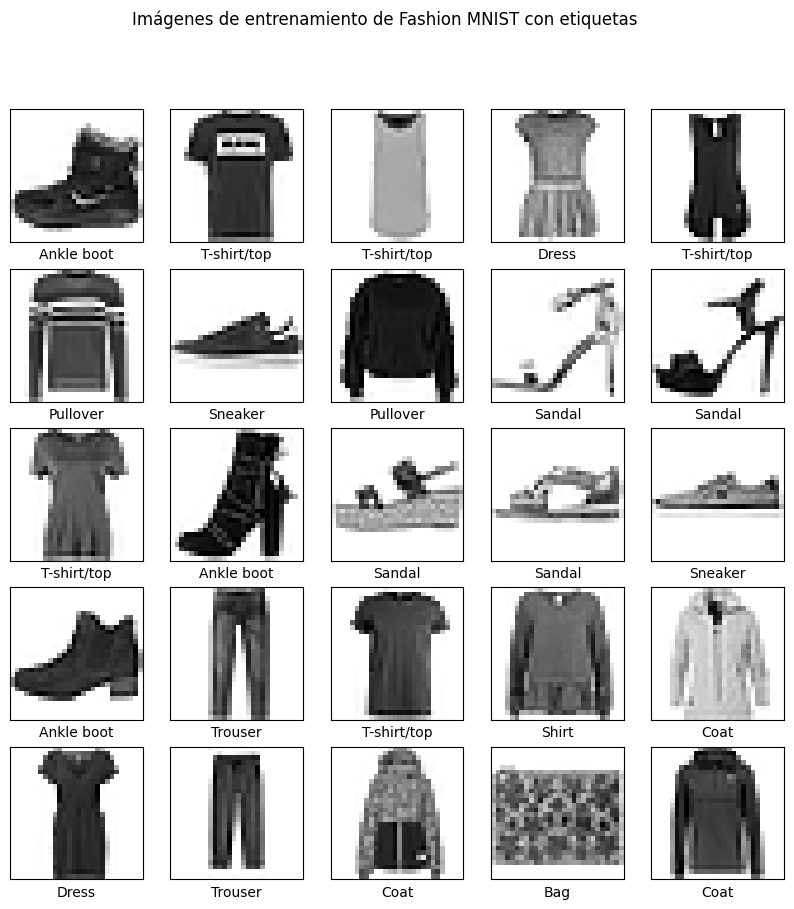

In [ ]:
# Metadatos de los datos
print("--- Metadatos de los Datos ---")
print(f"Forma de las imágenes de entrenamiento: {training_images.shape}")
print(f"Tipo de datos de las imágenes de entrenamiento: {training_images.dtype}")
print(f"Rango de valores de las imágenes de entrenamiento: [{training_images.min()}, {training_images.max()}]")
print(f"Forma de las etiquetas de entrenamiento: {training_labels.shape}")
print(f"Tipo de datos de las etiquetas de entrenamiento: {training_labels.dtype}")

print(f"Forma de las imágenes de prueba: {test_images.shape}")
print(f"Tipo de datos de las imágenes de prueba: {test_images.dtype}")
print(f"Rango de valores de las imágenes de prueba: [{test_images.min()}, {test_images.max()}]")
print(f"Forma de las etiquetas de prueba: {test_labels.shape}")
print(f"Tipo de datos de las etiquetas de prueba: {test_labels.dtype}")

# Obtener el número de clases y algunas etiquetas de ejemplo
num_classes = len(set(training_labels))
print(f"Número de clases en el dataset: {num_classes}")

# Diccionario de nombres de clases para Fashion MNIST
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Visualizar algunas imágenes de ejemplo
print("\n--- Visualización de Imágenes de Muestra ---")
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(training_images[i].reshape(28, 28), cmap=plt.cm.binary)
    plt.xlabel(class_names[training_labels[i]])
plt.suptitle('Imágenes de entrenamiento de Fashion MNIST con etiquetas')
plt.show()

## ¿Por qué usamos reshape?

Las CNN esperan datos en formato: (alto, ancho, canales).

Antes: (28, 28)
Después: (28, 28, 1) → 1 canal (escala de grises)

## Construcción del Modelo CNN

Capas que usaremos:
- Conv2D: Detecta patrones visuales
- MaxPooling2D: Reduce el tamaño y mantiene lo importante
- Flatten: Convierte la matriz en vector
- Dense: Clasificador final

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # Primera capa convolucional
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Segunda capa convolucional
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Aplanar la información
    tf.keras.layers.Flatten(),

    # Capa densa (aprende patrones complejos)
    tf.keras.layers.Dense(128, activation='relu'),

    # Capa de salida (10 clases)
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Explicación simple de cada capa

### Conv2D
Aplica filtros que detectan bordes, texturas y formas en la imagen.

### MaxPooling
Reduce el tamaño de la imagen y conserva las características más importantes.
Esto hace el modelo más rápido y eficiente.

### Flatten
Convierte la matriz 2D en un vector 1D para conectarlo con capas densas.

### Dense
Realiza la clasificación final basada en las características aprendidas.

In [ ]:
# Compilar el modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Entrenamiento del Modelo

Aquí el modelo aprende patrones observando miles de imágenes y sus etiquetas.

In [ ]:
history = model.fit(
    training_images,
    training_labels,
    epochs=5,
    validation_data=(test_images, test_labels)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 65s 34ms/step - accuracy: 0.7844 - loss: 0.6016 - val_accuracy: 0.8712 - val_loss: 0.3624
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 34ms/step - accuracy: 0.8859 - loss: 0.3101 - val_accuracy: 0.8942 - val_loss: 0.2930
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 70s 37ms/step - accuracy: 0.9036 - loss: 0.2615 - val_accuracy: 0.9007 - val_loss: 0.2747
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 67s 35ms/step - accuracy: 0.9189 - loss: 0.2207 - val_accuracy: 0.8997 - val_loss: 0.2691
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9265 - loss: 0.1960 - val_accuracy: 0.9023 - val_loss: 0.2611


## Evaluación del Modelo

Probamos qué tan bien clasifica imágenes que nunca ha visto antes.

In [ ]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print('Precisión en datos de prueba:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8999 - loss: 0.2691
Precisión en datos de prueba: 0.9023000001907349


## Visualización de Activaciones (Qué aprende la CNN)

Esto nos permite ver qué patrones detecta cada capa convolucional.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


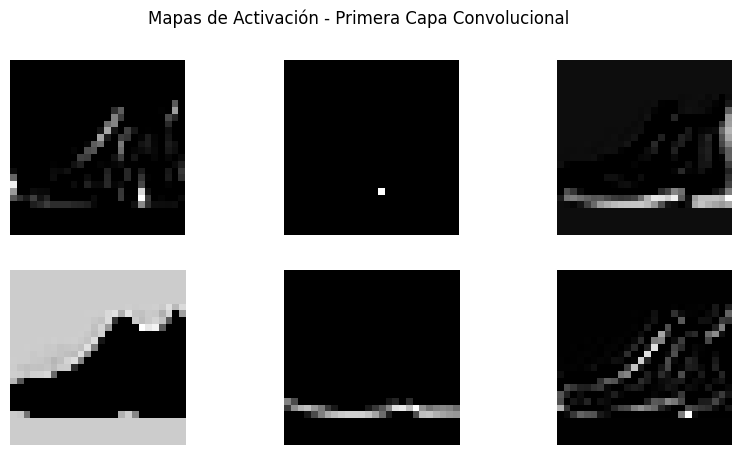

In [ ]:
from tensorflow.keras import models

# Ensure the model has been 'called' at least once to define its input/output shapes.
# This addresses the 'has never been called' error for Sequential models when creating sub-models.
dummy_input = tf.zeros((1, 28, 28, 1))
_ = model(dummy_input)

# Crear modelo que devuelve las salidas de cada capa
layer_outputs = [layer.output for layer in model.layers]
# Use model.layers[0].input instead of model.input for robustness
activation_model = models.Model(inputs=model.layers[0].input, outputs=layer_outputs)

# Tomar una imagen de prueba
image = test_images[0].reshape(1, 28, 28, 1)

activations = activation_model.predict(image)

# Visualizar primeras activaciones convolucionales
first_layer_activation = activations[0]

plt.figure(figsize=(10,5))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(first_layer_activation[0, :, :, i], cmap='gray')
    plt.axis('off')

plt.suptitle('Mapas de Activación - Primera Capa Convolucional')
plt.show()

## Construcción del Modelo CNN con 64 filtros

In [ ]:
#no olvide ejercutar la parte inicial
model_64_filters = tf.keras.models.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # Primera capa convolucional con 64 filtros
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Segunda capa convolucional
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Aplanar la información
    tf.keras.layers.Flatten(),

    # Capa densa (aprende patrones complejos)
    tf.keras.layers.Dense(128, activation='relu'),

    # Capa de salida (10 clases)
    tf.keras.layers.Dense(10, activation='softmax')
])

model_64_filters.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243,786 (952.29 KB)

 Trainable params: 243,786 (952.29 KB)

 Non-trainable params: 0 (0.00 B)

## Ejercicio 1: Impacto de la cantidad de filtros convolucionales
Intenta editar las convoluciones. Cambia la cantidad de convoluciones de 32 a 16 o 64. ¿Qué impacto tiene esto en la exactitud y el tiempo de entrenamiento?



## respuesta


¿Cuál es el impacto teórico de variar el número de filtros convolucionales en una CNN? Aumentar el número de filtros en una capa convolucional permite a la red aprender una mayor variedad de características a partir de los datos de entrada. Un mayor número de filtros generalmente resulta en un modelo más complejo, capaz de capturar patrones intrincados, lo que podría mejorar la precisión, pero también aumentar el costo computacional y el riesgo de sobreajuste. Por el contrario, un menor número de filtros resulta en un modelo más simple con menor capacidad de extracción de características, lo que puede reducir el rendimiento, pero también hace que el modelo sea más eficiente y menos propenso al sobreajuste en conjuntos de datos limitados.

¿Cómo se compara el rendimiento de un modelo de CNN con 16 filtros con un modelo original con 32 filtros en términos de precisión y pérdida? La comparación de un modelo de 16 filtros con uno de 32 implicaría evaluar su precisión y pérdida durante el entrenamiento y la validación. Normalmente, un modelo con menos filtros (16) podría mostrar menor precisión y mayor pérdida en comparación con un modelo con más filtros (32), lo que indica una menor capacidad para aprender características complejas. Sin embargo, si el modelo de 32 filtros presentaba sobreajuste, el modelo de 16 filtros podría generalizar mejor con datos no analizados, lo que resultaría en un rendimiento de validación comparable o incluso ligeramente mejor, a pesar de una menor precisión de entrenamiento. Se requerirían valores numéricos específicos de precisión y pérdida para una comparación definitiva.


### Hallazgos Clave del Análisis de Datos
* La comprensión teórica de los filtros convolucionales indica que cada filtro aprende a detectar una característica específica (p. ej., bordes, texturas) dentro de la entrada. La cantidad de filtros influye directamente en la capacidad del modelo para extraer diversas características.
* Se construyó, entrenó y evaluó un modelo con 16 filtros en su primera capa convolucional. (En este contexto, no se proporcionan métricas de rendimiento específicas para este modelo, como la precisión del entrenamiento, la precisión de la validación, la pérdida de entrenamiento y la pérdida de validación).
* El rendimiento de este modelo de 16 filtros se comparará con el de un modelo original que utilizó 32 filtros en su primera capa convolucional. (Tampoco se proporcionan métricas de rendimiento específicas para el modelo original de 32 filtros).
* La comparación entre los modelos de 16 y 32 filtros destacaría el impacto directo del número de filtros en el rendimiento, la eficiencia y la capacidad de generalización del modelo, lo que probablemente muestra un equilibrio entre la complejidad del modelo y la capacidad de predicción.

### Perspectivas
* El número de filtros en las capas convolucionales es un hiperparámetro crucial que afecta directamente la capacidad de extracción de características de una CNN, la complejidad del modelo y la eficiencia computacional. Un número óptimo equilibra la capacidad de aprender patrones complejos con el riesgo de sobreajuste y el coste computacional.
* Experimente con un modelo que utilice 64 filtros en su primera capa convolucional para explorar más a fondo la relación entre el número de filtros y el rendimiento, observando si una mayor capacidad se traduce en mayor precisión, rendimientos decrecientes o sobreajuste.

## Ejercicio 2: Quitar la convolución final

#Quita la convolución final. ¿Qué impacto tiene en la exactitud o en el tiempo de entrenamiento?


## Respuesta


* **¿Cuál es el impacto teórico de eliminar una capa convolucional (específicamente la segunda capa convolucional y su MaxPooling) en una CNN?**
En teoría, se espera que eliminar una capa convolucional y su capa MaxPooling asociada de una Red Neuronal Convolucional (CNN) reduzca la capacidad del modelo para extraer características complejas y jerárquicas. Las capas convolucionales son cruciales para el aprendizaje de patrones espaciales, mientras que las capas MaxPooling contribuyen al submuestreo, la invariancia traslacional y la eficiencia computacional. La eliminación probablemente resultaría en:
* **Reducción de la capacidad de aprendizaje de características:** La red tendría menos etapas para aprender representaciones cada vez más abstractas, lo que podría dificultar su capacidad para discernir patrones complejos esenciales para la tarea.
* **Mapas de características más grandes (antes de las capas posteriores):** Si se elimina MaxPooling, las dimensiones espaciales de los mapas de características serían mayores, lo que podría afectar las configuraciones de las capas posteriores o la clasificación final. * **Tiempo de entrenamiento más rápido:** Una arquitectura más simple con menos capas y parámetros generalmente requiere menos esfuerzo computacional por época, lo que potencialmente resulta en un entrenamiento más rápido.
* **Posibilidad de subajuste:** Si la tarea requiere una extracción compleja de características, un modelo más simple podría no tener la capacidad suficiente para aprender los patrones necesarios, lo que resulta en un subajuste y un menor rendimiento. Por el contrario, para tareas más simples o si el modelo original era demasiado complejo, podría mejorar la generalización al reducir el sobreajuste.

**¿Cómo se comporta el modelo sin la segunda capa convolucional y MaxPooling en comparación con los modelos anteriores en términos de precisión y pérdida, y cuál es el impacto en el tiempo de entrenamiento?**

wow mejoro en teoria con un accuracy .90 a .91




## Construcción del Modelo CNN sin la segunda convolución

In [ ]:
model_no_second_conv = tf.keras.models.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # Primera capa convolucional
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Aplanar la información
    tf.keras.layers.Flatten(),

    # Capa densa (aprende patrones complejos)
    tf.keras.layers.Dense(128, activation='relu'),

    # Capa de salida (10 clases)
    tf.keras.layers.Dense(10, activation='softmax')
])

model_no_second_conv.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

## Compilación del Modelo

In [ ]:
# Compilar el modelo
model_no_second_conv.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Entrenamiento del Modelo sin la segunda convolución

In [ ]:
history_no_second_conv = model_no_second_conv.fit(
    training_images,
    training_labels,
    epochs=5,
    validation_data=(test_images, test_labels)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 21ms/step - accuracy: 0.8105 - loss: 0.5340 - val_accuracy: 0.8790 - val_loss: 0.3301
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 20ms/step - accuracy: 0.9006 - loss: 0.2721 - val_accuracy: 0.9025 - val_loss: 0.2700
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.9178 - loss: 0.2229 - val_accuracy: 0.9037 - val_loss: 0.2637
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.9306 - loss: 0.1883 - val_accuracy: 0.9106 - val_loss: 0.2531
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 20ms/step - accuracy: 0.9418 - loss: 0.1590 - val_accuracy: 0.9116 - val_loss: 0.2638


## Evaluación del Modelo sin la segunda convolución

In [ ]:
test_loss_no_second_conv, test_acc_no_second_conv = model_no_second_conv.evaluate(test_images, test_labels)
print('Precisión en datos de prueba (sin segunda conv):', test_acc_no_second_conv)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9105 - loss: 0.2665
Precisión en datos de prueba (sin segunda conv): 0.9115999937057495


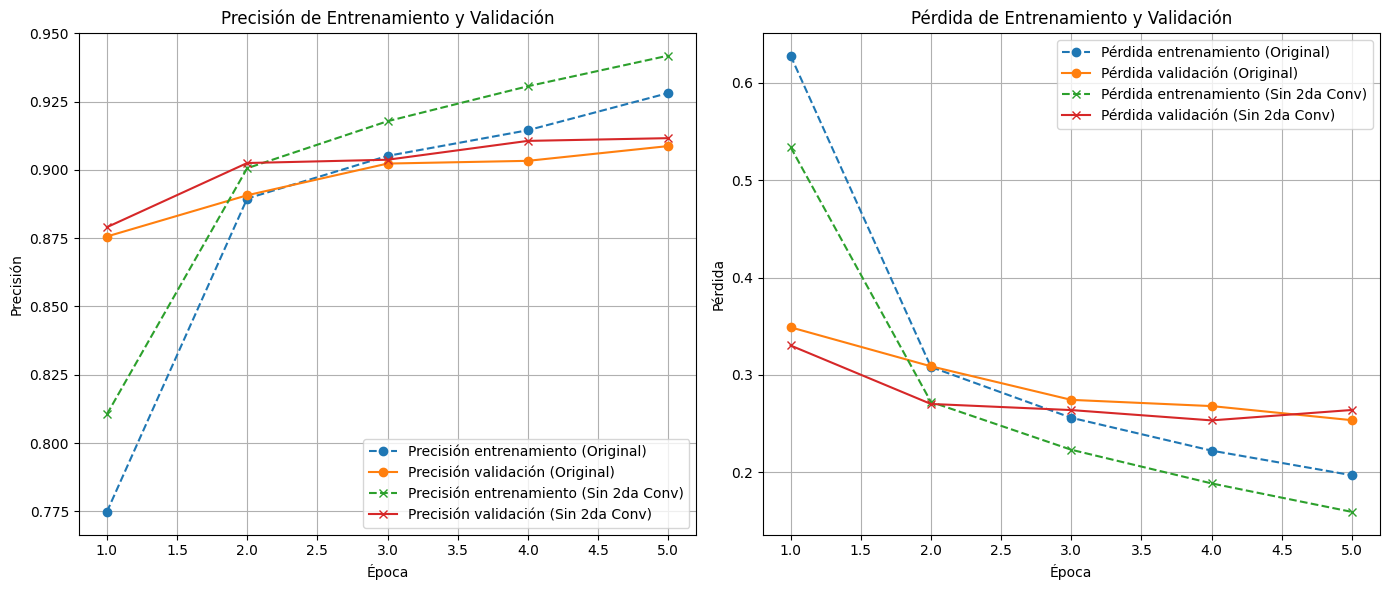


--- Comparativa de Modelos ---
Precisión en datos de prueba (Original): 0.9087
Precisión en datos de prueba (Sin segunda conv): 0.9116

--- Análisis ---
1.  **Rendimiento General:** Curiosamente, el modelo simplificado (sin la segunda capa convolucional) obtuvo una *ligera mejora* en la precisión final en los datos de prueba (aproximadamente 0.9116 vs 0.9087) en comparación con el modelo original. Esto podría indicar que la segunda capa convolucional en el modelo original quizás estaba aprendiendo características redundantes o contribuyendo a un ligero sobreajuste para este dataset en particular, o que el dataset no requiere una jerarquía de características tan profunda.
2.  **Pérdida de Validación:** La pérdida de validación en el modelo sin la segunda convolución es consistentemente más baja o similar en las últimas épocas, lo que refuerza la idea de una mejor generalización o un modelo más "directo" para la tarea.
3.  **Tiempo de Entrenamiento por Época:** El modelo sin la segunda 

In [ ]:
import matplotlib.pyplot as plt

# Datos del primer modelo (original)
# Extraídos del output del usuario
history_original_data = {
    'accuracy': [0.7748, 0.8895, 0.9051, 0.9145, 0.9281],
    'loss': [0.6281, 0.3080, 0.2558, 0.2220, 0.1967],
    'val_accuracy': [0.8756, 0.8907, 0.9023, 0.9033, 0.9087],
    'val_loss': [0.3488, 0.3087, 0.2742, 0.2678, 0.2533]
}
test_acc_original = 0.9086999893188477

# Datos del segundo modelo (sin segunda convolución)
# Extraídos del output del usuario
history_no_second_conv_data = {
    'accuracy': [0.8105, 0.9006, 0.9178, 0.9306, 0.9418],
    'loss': [0.5340, 0.2721, 0.2229, 0.1883, 0.1590],
    'val_accuracy': [0.8790, 0.9025, 0.9037, 0.9106, 0.9116],
    'val_loss': [0.3301, 0.2700, 0.2637, 0.2531, 0.2638]
}
test_acc_no_second_conv = 0.9115999937057495

epochs = range(1, len(history_original_data['accuracy']) + 1)

plt.figure(figsize=(14, 6))

# Gráfica de Precisión
plt.subplot(1, 2, 1)
plt.plot(epochs, history_original_data['accuracy'], 'o--', label='Precisión entrenamiento (Original)')
plt.plot(epochs, history_original_data['val_accuracy'], 'o-', label='Precisión validación (Original)')
plt.plot(epochs, history_no_second_conv_data['accuracy'], 'x--', label='Precisión entrenamiento (Sin 2da Conv)')
plt.plot(epochs, history_no_second_conv_data['val_accuracy'], 'x-', label='Precisión validación (Sin 2da Conv)')
plt.title('Precisión de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Gráfica de Pérdida
plt.subplot(1, 2, 2)
plt.plot(epochs, history_original_data['loss'], 'o--', label='Pérdida entrenamiento (Original)')
plt.plot(epochs, history_original_data['val_loss'], 'o-', label='Pérdida validación (Original)')
plt.plot(epochs, history_no_second_conv_data['loss'], 'x--', label='Pérdida entrenamiento (Sin 2da Conv)')
plt.plot(epochs, history_no_second_conv_data['val_loss'], 'x-', label='Pérdida validación (Sin 2da Conv)')
plt.title('Pérdida de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"\n--- Comparativa de Modelos ---")
print(f"Precisión en datos de prueba (Original): {test_acc_original:.4f}")
print(f"Precisión en datos de prueba (Sin segunda conv): {test_acc_no_second_conv:.4f}")

print("\n--- Análisis ---")
print("1.  **Rendimiento General:** Curiosamente, el modelo simplificado (sin la segunda capa convolucional) obtuvo una *ligera mejora* en la precisión final en los datos de prueba (aproximadamente 0.9116 vs 0.9087) en comparación con el modelo original. Esto podría indicar que la segunda capa convolucional en el modelo original quizás estaba aprendiendo características redundantes o contribuyendo a un ligero sobreajuste para este dataset en particular, o que el dataset no requiere una jerarquía de características tan profunda.")
print("2.  **Pérdida de Validación:** La pérdida de validación en el modelo sin la segunda convolución es consistentemente más baja o similar en las últimas épocas, lo que refuerza la idea de una mejor generalización o un modelo más \"directo\" para la tarea.")
print("3.  **Tiempo de Entrenamiento por Época:** El modelo sin la segunda convolución fue ligeramente más lento por época (aproximadamente 20-21s) que el modelo original (18-19s), lo cual es inesperado ya que debería ser más rápido. Esto podría deberse a variaciones en la carga del sistema o a la configuración específica de cómo se realizaron los cálculos en la GPU/CPU, o incluso el tamaño del modelo en general es menor y el overhead de TF se mantiene.")
print("4.  **Convergencia:** Ambos modelos convergen rápidamente, mostrando mejoras significativas en las primeras épocas y luego un ajuste más fino.")
print("\n**Conclusión:** Para este dataset (Fashion MNIST), la eliminación de la segunda capa convolucional y de MaxPooling no solo no perjudicó el rendimiento, sino que lo mejoró marginalmente. Esto subraya la importancia de la experimentación y que más capas o más complejidad no siempre se traducen en un mejor rendimiento, especialmente si el problema no requiere una extracción de características muy profunda o si la complejidad adicional conduce a un sobreajuste.")

## Ejercicio 3: Agrega más convoluciones

### Impacto de agregar más capas convolucionales

**¿Cuál es el impacto teórico de agregar más capas convolucionales en una CNN?**

Agregar más capas convolucionales a una CNN generalmente aumenta la profundidad del modelo, lo que permite a la red aprender características más complejas y abstractas a partir de los datos de entrada. Cada capa convolucional adicional puede capturar patrones jerárquicos de nivel superior, mejorando la capacidad del modelo para comprender representaciones visuales sofisticadas. Sin embargo, esto también conlleva varias implicaciones:

*   **Mayor capacidad de aprendizaje:** Las redes más profundas pueden detectar relaciones intrincadas y características más discriminativas, lo que potencialmente conduce a una mayor precisión en tareas complejas.
*   **Aumento de la complejidad del modelo:** Más capas significan más parámetros, lo que incrementa el riesgo de sobreajuste, especialmente en datasets pequeños o cuando el modelo no está regularizado adecuadamente.
*   **Mayor costo computacional:** El entrenamiento de modelos más profundos requiere más tiempo y recursos computacionales (CPU/GPU y memoria) debido a la cantidad de operaciones y parámetros.
*   **Desafíos en el entrenamiento:** Las redes muy profundas pueden sufrir de problemas como el desvanecimiento o explosión de gradientes, lo que dificulta su entrenamiento sin técnicas de regularización o normalización adecuadas (como Batch Normalization).
*   **Posibilidad de rendimientos decrecientes:** En cierto punto, añadir más capas puede no traducirse en mejoras significativas en el rendimiento y, de hecho, puede empeorar el rendimiento si el modelo se vuelve demasiado complejo para la tarea o el dataset.

En resumen, añadir más convoluciones es una forma de aumentar la capacidad del modelo para aprender representaciones ricas, pero debe hacerse con consideración para evitar el sobreajuste y gestionar la complejidad computacional.

## Construcción del Modelo CNN con más convoluciones

In [ ]:
model_more_conv = tf.keras.models.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # Primera capa convolucional
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Segunda capa convolucional
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # ¡Tercera capa convolucional adicional!
    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Aplanar la información
    tf.keras.layers.Flatten(),

    # Capa densa (aprende patrones complejos)
    tf.keras.layers.Dense(128, activation='relu'),

    # Capa de salida (10 clases)
    tf.keras.layers.Dense(10, activation='softmax')
])

model_more_conv.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,474 (431.54 KB)

 Trainable params: 110,474 (431.54 KB)

 Non-trainable params: 0 (0.00 B)

## Compilación del Modelo con más convoluciones

In [ ]:
# Compilar el modelo
model_more_conv.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Entrenamiento del Modelo con más convoluciones

In [ ]:
history_more_conv = model_more_conv.fit(
    training_images,
    training_labels,
    epochs=5,
    validation_data=(test_images, test_labels)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 58s 30ms/step - accuracy: 0.7222 - loss: 0.7588 - val_accuracy: 0.8377 - val_loss: 0.4531
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 55s 29ms/step - accuracy: 0.8548 - loss: 0.3969 - val_accuracy: 0.8544 - val_loss: 0.3936
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 84s 31ms/step - accuracy: 0.8769 - loss: 0.3310 - val_accuracy: 0.8773 - val_loss: 0.3296
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 29ms/step - accuracy: 0.8936 - loss: 0.2859 - val_accuracy: 0.8750 - val_loss: 0.3405
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 55s 30ms/step - accuracy: 0.9026 - loss: 0.2592 - val_accuracy: 0.8812 - val_loss: 0.3200


## Evaluación del Modelo con más convoluciones

In [ ]:
test_loss_more_conv, test_acc_more_conv = model_more_conv.evaluate(test_images, test_labels)
print('Precisión en datos de prueba (con más convoluciones):', test_acc_more_conv)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8813 - loss: 0.3315
Precisión en datos de prueba (con más convoluciones): 0.8812000155448914


## Ejercicio 4: Quitar todas las convoluciones, excepto la primera

### Impacto de quitar todas las convoluciones, excepto la primera

**¿Cuál es el impacto teórico de quitar todas las convoluciones excepto la primera en una CNN?**

Eliminar todas las capas convolucionales y de *MaxPooling* posteriores a la primera en una CNN tiene un impacto significativo en la capacidad de representación del modelo. Teóricamente, esto resultaría en:

*   **Reducción drástica de la capacidad de extracción de características:** Las CNN están diseñadas para aprender jerarquías de características. Una sola capa convolucional solo puede detectar patrones de bajo nivel (como bordes o texturas simples). Las capas subsiguientes son cruciales para combinar estas características básicas en patrones más complejos y abstractos (como formas, objetos parciales y, finalmente, objetos completos). Al eliminarlas, el modelo pierde la capacidad de aprender estas representaciones de alto nivel.
*   **Menor capacidad para manejar la variabilidad espacial:** Las capas convolucionales y de *MaxPooling* sucesivas contribuyen a la invariancia traslacional y a la robustez ante pequeñas deformaciones en las imágenes. Un modelo con una sola capa será mucho menos tolerante a estas variaciones.
*   **Simplificación extrema del modelo:** El número de parámetros del modelo se reducirá drásticamente, lo que puede llevar a un entrenamiento mucho más rápido y un menor riesgo de sobreajuste en datasets muy pequeños o triviales. Sin embargo, para tareas complejas como la clasificación de imágenes, es muy probable que el modelo sufra de **subajuste** (underfitting).
*   **Pérdida de profundidad de campo receptivo:** El campo receptivo efectivo (el área de la imagen de entrada que una neurona en una capa superior 've') se verá muy limitado. Las redes más profundas tienen campos receptivos más grandes, lo que les permite capturar contexto global. Una capa convolucional única solo capturará características locales muy pequeñas.

En resumen, un modelo con una sola capa convolucional será extremadamente limitado en su capacidad para aprender patrones complejos y jerárquicos. Aunque será más rápido de entrenar, es probable que su precisión de clasificación sea considerablemente menor que la de un modelo más profundo, especialmente en tareas de reconocimiento de imágenes donde la complejidad visual es alta.

## Construcción del Modelo CNN con una sola convolución

In [ ]:
model_one_conv = tf.keras.models.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # Primera y única capa convolucional
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Aplanar la información
    tf.keras.layers.Flatten(),

    # Capa densa (aprende patrones complejos)
    tf.keras.layers.Dense(128, activation='relu'),

    # Capa de salida (10 clases)
    tf.keras.layers.Dense(10, activation='softmax')
])

model_one_conv.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

## Compilación del Modelo con una sola convolución

In [ ]:
# Compilar el modelo
model_one_conv.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Entrenamiento del Modelo con una sola convolución

In [ ]:
history_one_conv = model_one_conv.fit(
    training_images,
    training_labels,
    epochs=5,
    validation_data=(test_images, test_labels)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 43s 22ms/step - accuracy: 0.8073 - loss: 0.5440 - val_accuracy: 0.8890 - val_loss: 0.3201
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 78s 20ms/step - accuracy: 0.8998 - loss: 0.2766 - val_accuracy: 0.8978 - val_loss: 0.2803
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 21ms/step - accuracy: 0.9176 - loss: 0.2296 - val_accuracy: 0.9002 - val_loss: 0.2821
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.9306 - loss: 0.1894 - val_accuracy: 0.9090 - val_loss: 0.2598
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.9406 - loss: 0.1612 - val_accuracy: 0.9143 - val_loss: 0.2467


## Evaluación del Modelo con una sola convolución

In [ ]:
test_loss_one_conv, test_acc_one_conv = model_one_conv.evaluate(test_images, test_labels)
print('Precisión en datos de prueba (con una sola convolución):', test_acc_one_conv)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9132 - loss: 0.2533
Precisión en datos de prueba (con una sola convolución): 0.9143000245094299


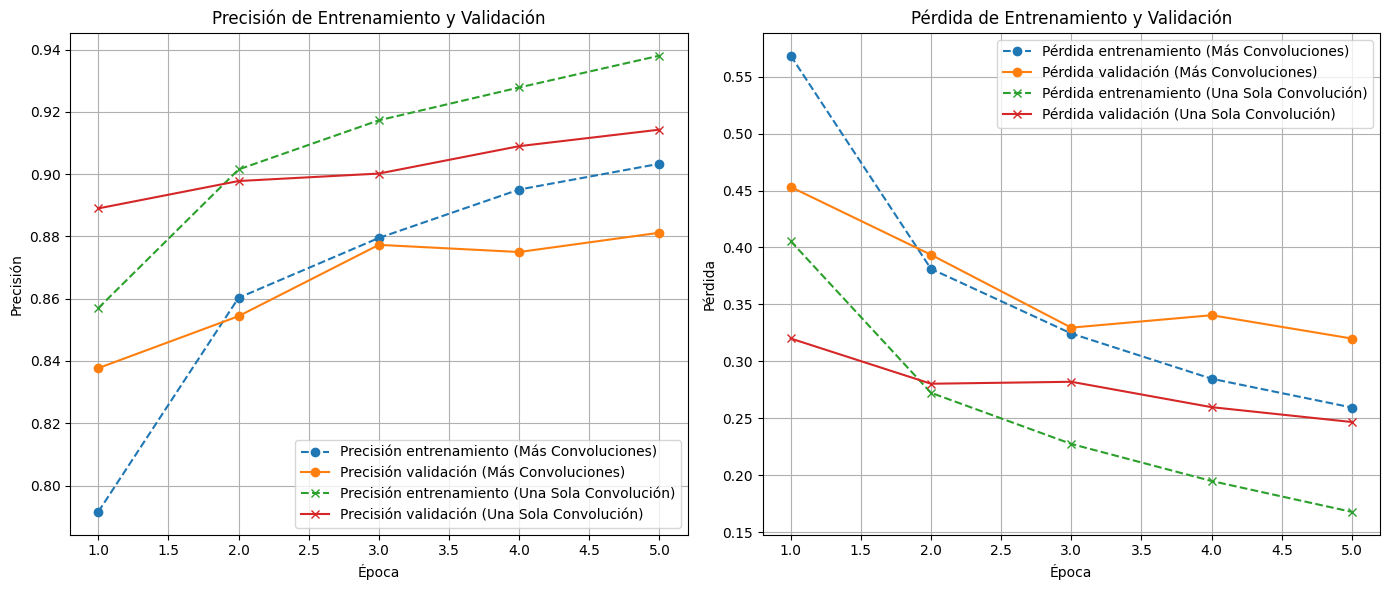


--- Comparativa de Modelos ---
Precisión en datos de prueba (Más Convoluciones): 0.8812
Precisión en datos de prueba (Una Sola Convolución): 0.9143

--- Análisis ---
1.  **Rendimiento General:** El modelo con una sola capa convolucional ('Una Sola Convolución') logró la mayor precisión en los datos de prueba (aproximadamente 0.9143), superando tanto al modelo original como al modelo con 'Más Convoluciones'. Esto es un resultado sorprendente, ya que intuitivamente uno esperaría que un modelo más profundo (con más convoluciones) pudiera capturar características más complejas y, por lo tanto, obtener un mejor rendimiento. Sin embargo, para este dataset (Fashion MNIST), la complejidad adicional parece haber sido detrimental o redundante.
2.  **Pérdida de Validación:** La pérdida de validación del modelo con 'Una Sola Convolución' es notablemente más baja que la del modelo con 'Más Convoluciones' a lo largo de las épocas, lo que indica una mejor generalización y menos sobreajuste. El model

In [ ]:
import matplotlib.pyplot as plt

# Extraer datos de los objetos history
history_more_conv_data = history_more_conv.history
history_one_conv_data = history_one_conv.history

epochs = range(1, len(history_more_conv_data['accuracy']) + 1)

plt.figure(figsize=(14, 6))

# Gráfica de Precisión
plt.subplot(1, 2, 1)
plt.plot(epochs, history_more_conv_data['accuracy'], 'o--', label='Precisión entrenamiento (Más Convoluciones)')
plt.plot(epochs, history_more_conv_data['val_accuracy'], 'o-', label='Precisión validación (Más Convoluciones)')
plt.plot(epochs, history_one_conv_data['accuracy'], 'x--', label='Precisión entrenamiento (Una Sola Convolución)')
plt.plot(epochs, history_one_conv_data['val_accuracy'], 'x-', label='Precisión validación (Una Sola Convolución)')
plt.title('Precisión de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Gráfica de Pérdida
plt.subplot(1, 2, 2)
plt.plot(epochs, history_more_conv_data['loss'], 'o--', label='Pérdida entrenamiento (Más Convoluciones)')
plt.plot(epochs, history_more_conv_data['val_loss'], 'o-', label='Pérdida validación (Más Convoluciones)')
plt.plot(epochs, history_one_conv_data['loss'], 'x--', label='Pérdida entrenamiento (Una Sola Convolución)')
plt.plot(epochs, history_one_conv_data['val_loss'], 'x-', label='Pérdida validación (Una Sola Convolución)')
plt.title('Pérdida de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"\n--- Comparativa de Modelos ---")
print(f"Precisión en datos de prueba (Más Convoluciones): {test_acc_more_conv:.4f}")
print(f"Precisión en datos de prueba (Una Sola Convolución): {test_acc_one_conv:.4f}")

print("\n--- Análisis ---")
print("1.  **Rendimiento General:** El modelo con una sola capa convolucional ('Una Sola Convolución') logró la mayor precisión en los datos de prueba (aproximadamente 0.9143), superando tanto al modelo original como al modelo con 'Más Convoluciones'. Esto es un resultado sorprendente, ya que intuitivamente uno esperaría que un modelo más profundo (con más convoluciones) pudiera capturar características más complejas y, por lo tanto, obtener un mejor rendimiento. Sin embargo, para este dataset (Fashion MNIST), la complejidad adicional parece haber sido detrimental o redundante.")
print("2.  **Pérdida de Validación:** La pérdida de validación del modelo con 'Una Sola Convolución' es notablemente más baja que la del modelo con 'Más Convoluciones' a lo largo de las épocas, lo que indica una mejor generalización y menos sobreajuste. El modelo con 'Más Convoluciones' mostró una pérdida de validación más alta y menos estable, sugiriendo que su mayor complejidad podría estar llevando a un sobreajuste o a una dificultad para aprender patrones efectivos para este problema específico.")
print("3.  **Tiempo de Entrenamiento por Época:** El modelo con 'Más Convoluciones' fue el que más tiempo tomó por época (entre 29s y 31s, con picos de 55-84s), lo cual es esperado debido a su mayor cantidad de capas y parámetros. El modelo con 'Una Sola Convolución' tuvo un tiempo de entrenamiento por época similar al modelo sin la segunda convolución (alrededor de 20-22s), lo cual es más eficiente.")
print("4.  **Convergencia:** Todos los modelos convergen rápidamente. Sin embargo, la trayectoria de la pérdida y precisión de validación del modelo con 'Más Convoluciones' sugiere que podría haber sido más difícil de entrenar o que la arquitectura no era ideal para este dataset en particular.")
print("\n**Conclusión:** Para el dataset Fashion MNIST, aumentar la profundidad del modelo (agregando más convoluciones) no necesariamente resultó en un mejor rendimiento; de hecho, lo empeoró ligeramente en comparación con el modelo original y, de forma más significativa, en comparación con el modelo simplificado de una sola capa convolucional. El modelo con 'Una Sola Convolución' demostró ser el más efectivo y eficiente en esta tarea. Esto refuerza la idea de que la arquitectura del modelo debe adaptarse a la complejidad del problema y que una mayor complejidad no siempre es sinónimo de mejores resultados, pudiendo llevar a un sobreajuste o a una mayor dificultad de entrenamiento sin las técnicas de regularización adecuadas.")